In [1]:
from pathlib import Path

from email_outreach.utils.constants import ROOT_FOLDER

# ============================== CONFIG ==============================
EXP_ROOT = ROOT_FOLDER / "experiments" / "test_set" / "1" / "contextual_bandit"

# display name -> folder with the experiment runs (order = plotting / table order)
EXPERIMENTS: dict[str, Path] = {
    "Baseline": EXP_ROOT / "baseline",
    "Recency Weighted phi": EXP_ROOT / "recency_weighted_phi",
}

REFERENCE = "Baseline"                          # deltas are computed vs. this experiment (None = no deltas)
N_POINTS = 101                                  # resolution of the recall/precision curves
HIGHLIGHT_X = [0.05, 0.15, 0.25, 0.35, 0.50, 0.75]   # points for the recall/precision tables
RECALL_TARGETS = [0.80, 0.90, 0.95]             # "x needed to reach recall >= target" table
ZOOM_X_MAX = 0.40                               # right edge of the zoomed plots
STD_DDOF = 0                                    # 0 = population std (as before), 1 = sample std
DECIMALS = 4
SAVE_DIR = None                                 # e.g. Path("figures") to also save PNGs
# ====================================================================

## Load experiments

In [2]:
from email_outreach.notes.experiment_summary import (
    load_experiments, show_summary_tables,
    plot_mean_curves, plot_recall_delta, plot_individual_runs, plot_auc,
)

results = load_experiments(EXPERIMENTS, n_points=N_POINTS, std_ddof=STD_DDOF, reference=REFERENCE)

Baseline: 100 runs loaded in 60s  (/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/experiments/test_set/1/contextual_bandit/baseline)
Recency Weighted phi: 100 runs loaded in 68s  (/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/src/email_outreach/experiments/test_set/1/contextual_bandit/recency_weighted_phi)


## Summary tables

In [3]:
show_summary_tables(results, highlight_x=HIGHLIGHT_X, recall_targets=RECALL_TARGETS,
                    reference=REFERENCE, decimals=DECIMALS)

### Recall AUC

,runs,AUC mean,AUC std,AUC min,AUC max,Δ AUC vs ref (pp)
Baseline,100.0,0.8934,0.0101,0.8631,0.9139,NaN
Recency Weighted phi,100.0,0.9083,0.0104,0.8790,0.9261,1.48


### Recall at selected points (mean ± std over runs; columns = x = 1 - quantile)

,0.05,0.15,0.25,0.35,0.50,0.75
Baseline,0.3664 ± 0.0643,0.8207 ± 0.0224,0.9223 ± 0.0126,0.9582 ± 0.0098,0.9749 ± 0.0076,0.9886 ± 0.0040
Recency Weighted phi,0.4927 ± 0.0388,0.8396 ± 0.0251,0.9306 ± 0.0139,0.9623 ± 0.0106,0.9751 ± 0.0080,0.9889 ± 0.0042


**Δ recall vs `Baseline` (pp)**

,0.05,0.15,0.25,0.35,0.50,0.75
Recency Weighted phi,12.63,1.89,0.83,0.41,0.01,0.03


... (2 outputs left out)

**Δ precision vs `Baseline` (pp)**

,0.05,0.15,0.25,0.35,0.50,0.75
Recency Weighted phi,12.17,0.61,0.16,0.06,0.0,0.0


### Smallest x at which the mean recall reaches the target (lower is better)

,recall ≥ 80%,recall ≥ 90%,recall ≥ 95%
Baseline,0.15,0.22,0.32
Recency Weighted phi,0.13,0.21,0.31


## Recall curves

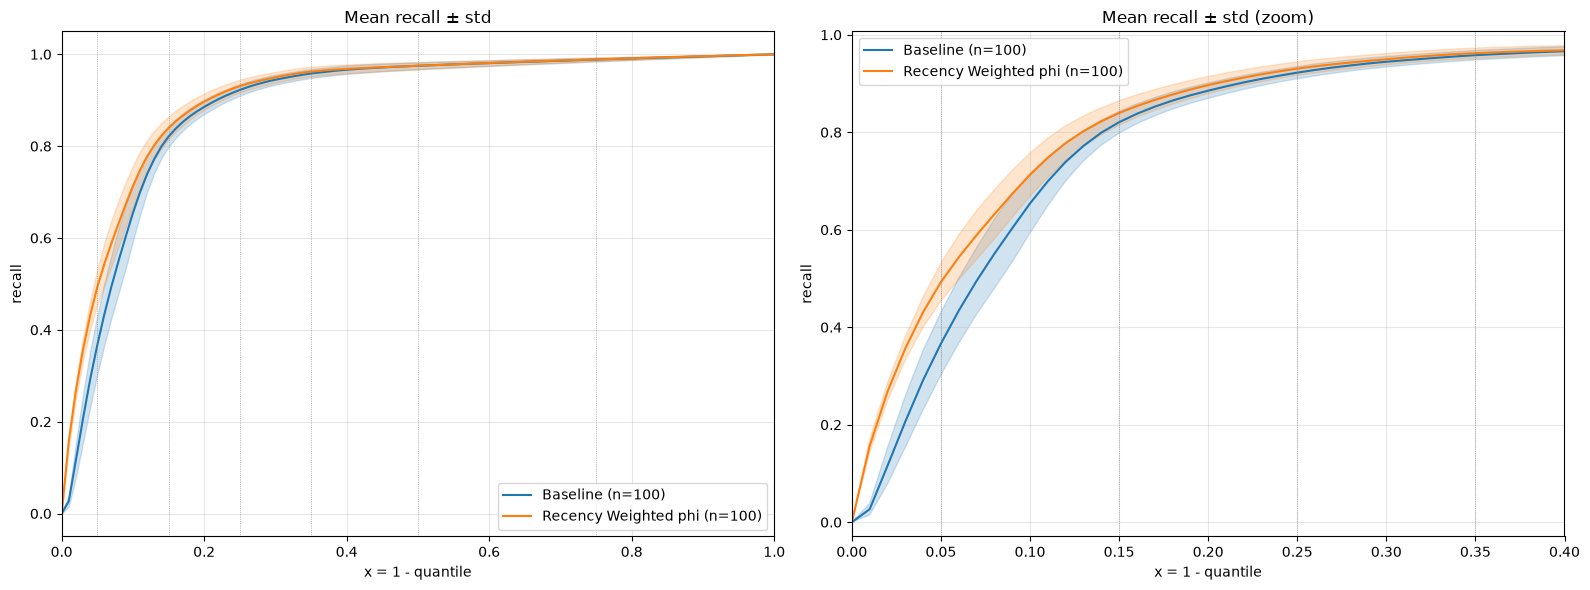

In [4]:
plot_mean_curves(results, kind="recall", highlight_x=HIGHLIGHT_X, zoom_x_max=ZOOM_X_MAX, save_dir=SAVE_DIR)

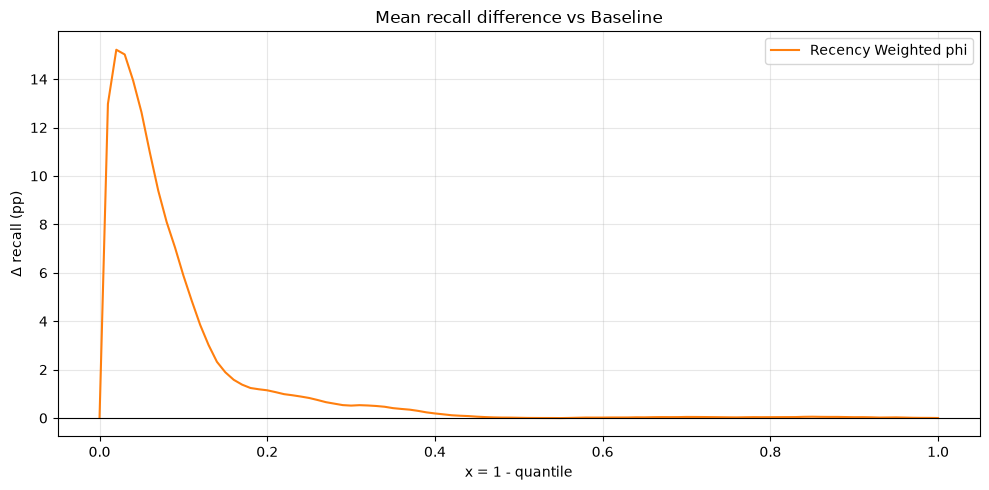

In [5]:
if REFERENCE is not None:
    plot_recall_delta(results, reference=REFERENCE, save_dir=SAVE_DIR)

## Individual runs overlaid

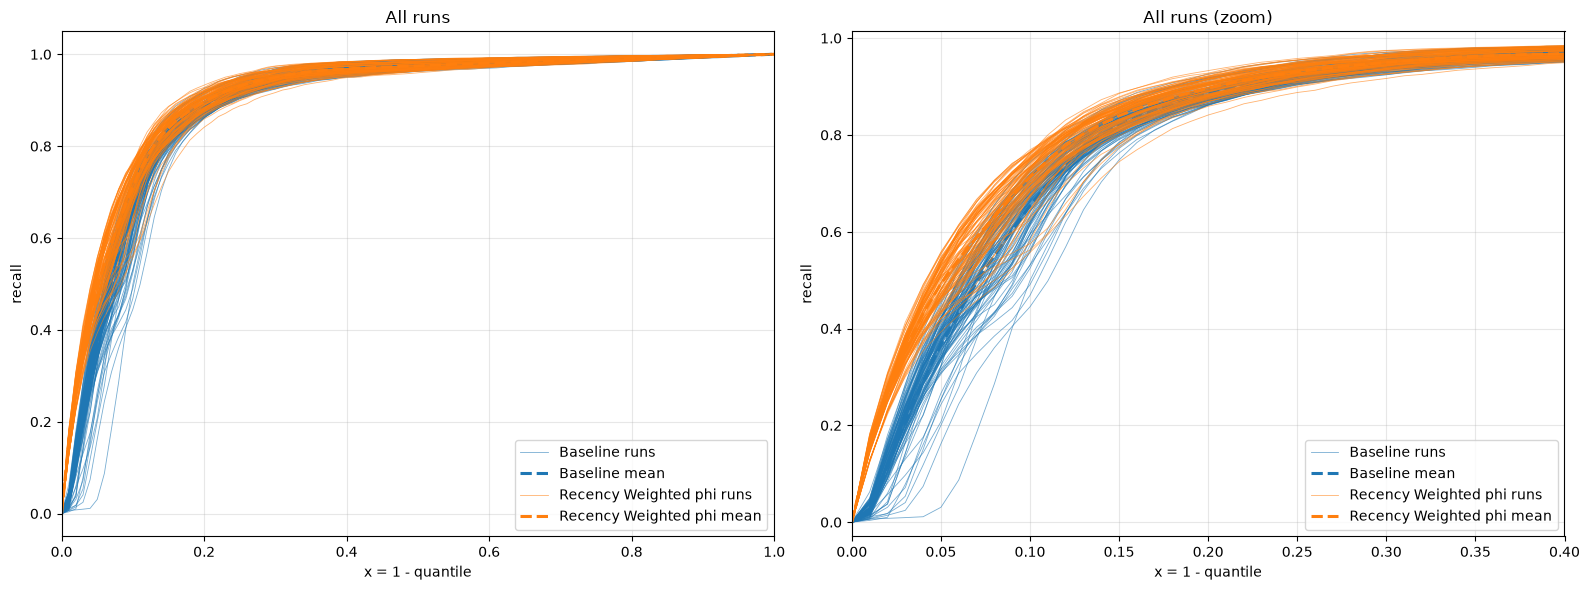

In [6]:
plot_individual_runs(results, kind="recall", zoom_x_max=ZOOM_X_MAX, save_dir=SAVE_DIR)

## Precision curves

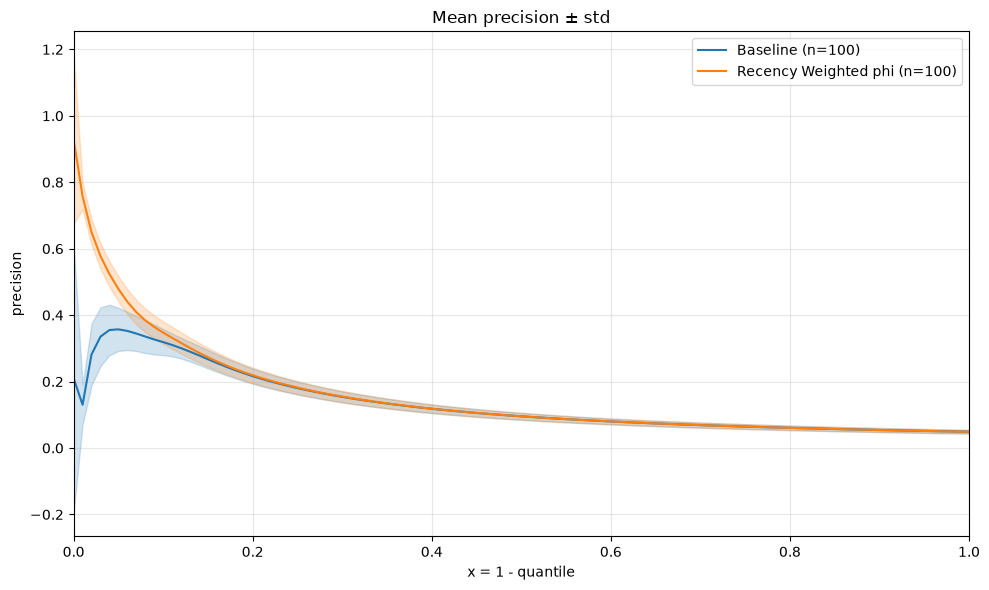

In [7]:
plot_mean_curves(results, kind="precision", save_dir=SAVE_DIR)

## Per-run AUC

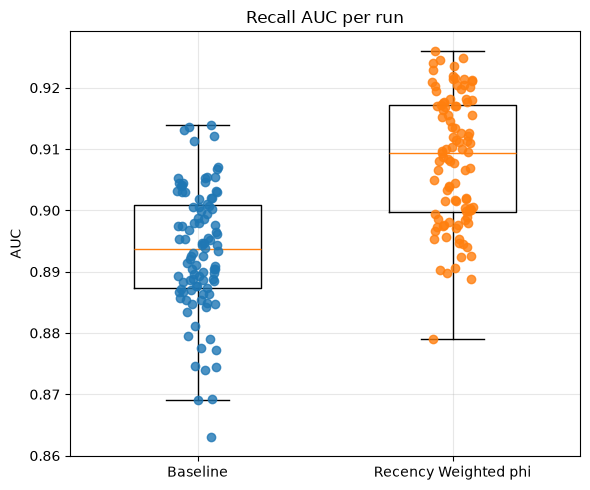

In [8]:
plot_auc(results, save_dir=SAVE_DIR)